# 04 — Phân tích giá gạo

Từng exact benchmark/quote series được phân tích riêng; không FX conversion, không trộn monetary prices với indices.

Environment: Windows host, Python 3.10–3.13; `pip install -r requirements/analytics.txt`.
Docker `tlcn-local` đã healthy, Windows available >=2 GiB, WSL >=3 GiB, không active writer/DagRun.
Không start Spark. Mỗi notebook chạy độc lập, theo thứ tự cells. Query names/typed filters hiển thị
trong retrieval cells; kết quả là full scoped results/aggregates, **không phải 20-row sample consumer**.
Source-scoped identities không phải official crosswalk. Không forward-fill/interpolate.

Chạy `python scripts/run_eda_notebooks.py --notebook <filename>` từ repo root để execute và cập nhật
Markdown diễn giải bằng đúng measured evidence. Kết quả Markdown ghi batch cố định bên trên;
publication đổi sẽ fail closed. Không dùng outputs cũ như live query cache.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/gold/consumer.py').exists())
sys.path.insert(0, str(ROOT/'src'))  # repository bootstrap, no credentials
import pandas as pd
import numpy as np
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from analytics.client import EDAClient
from analytics.methods import calendar_yoy, endpoint_change, monthly_calendar
from analytics.notebook import inspect_frame, label, resolve, annual_plot, save_evidence
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
client = EDAClient()
findings = []
inventory = client.query('publication')
EXPECTED_BATCH = 'ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235'
assert client.batch == EXPECTED_BATCH, 'Publication changed: review scope before reproducing EDA'
display(inventory)
print('Published batch:', client.batch, '| No query cache | Windows/WSL/writer gates checked per request')

,table,rows,uuid,snapshot_id
0,dim_date,2038,0d029553-197b-4e46-8d62-17f21334a11b,7665947661409225898
1,dim_month,800,4f262a83-5e36-4d9e-b7e0-18f91b46327f,8295574410069434036
2,dim_observation_type,34,8adc0a9f-498e-4503-aa05-f95ae5a358ed,1046146616745412073
3,dim_price_series,1042,fa39bf1e-bbf1-4b50-8129-de1d4f37413b,2896601742107309180
4,dim_source_geography,987,ce487b86-5541-44de-a006-365dfbcc29f2,8664595598201008097
5,dim_source_product,295,4ce4f42f-e876-4870-8b2a-0312c460d673,8514812747103222137
6,dim_source_system,9,3c9fdb0f-127a-45f4-8f5b-31c7d1d5c0c1,5212267582300439758
7,dim_year,67,032861f7-4c4e-4ac4-9a10-274670b1d694,3316235776078407392
8,fact_fao_price_annual,9993,3218dd14-0793-4c1d-941c-31ba5e1aaea8,6561274137596983252
9,fact_fao_production_observation,22738,f97e800f-ebe6-416c-918a-a148ec0388b4,4557995850181557281


Published batch: ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235 | No query cache | Windows/WSL/writer gates checked per request


## Câu hỏi 1 — World Bank rice_thai_5: mức giá và monthly volatility

In [2]:
series=client.query('catalogue',kind='series')
selected=series[series.series_identity_json.eq('["rice_thai_5"]')]
assert len(selected)==1
wb_key=selected.iloc[0].price_series_key
wb=client.query('price_observations',fact='fact_price_monthly',series=wb_key,start_period=200001,end_period=202512)

In [3]:
display(wb.shape,inspect_frame(wb),selected,wb.head())

(312, 12)

,dtype,nulls
observation_key,object,0
period,int64,0
reference_period,object,312
price_series_key,object,0
value,object,0
missing_reason,object,312
dq_warnings_json,object,0
series_identity_json,object,0
unit,object,0
currency,object,0


,price_series_key,source_system_key,series_identity_json,geography_key,product_key,price_type_source,unit,currency,price_kind,information_source
67,31277471ba383c2f64dc3e639466128f6b3503027d3465...,90bcf8f8d7300c31a6b53291b2928e34c9b6d63671bee0...,"[""rice_thai_5""]",0000000000000000000000000000000000000000000000...,317327dc12a1c83925646ad8de0fa3af6cc5f9694fd5cb...,benchmark,USD/tonne,USD,benchmark_price,None


,observation_key,period,reference_period,price_series_key,value,missing_reason,dq_warnings_json,series_identity_json,unit,currency,price_kind,information_source
0,260bfe55701191f3a6025aa60a6f022f4b586909a4360f...,201202,None,31277471ba383c2f64dc3e639466128f6b3503027d3465...,537.5000,None,[],"[""rice_thai_5""]",USD/tonne,USD,benchmark_price,None
1,f3063d7ddb826c304195409f736e52dd99385152b553c5...,201203,None,31277471ba383c2f64dc3e639466128f6b3503027d3465...,548.0000,None,[],"[""rice_thai_5""]",USD/tonne,USD,benchmark_price,None
2,374b0afdd4de6cf283c7f9ec8e2fddd65f16ed50202384...,201204,None,31277471ba383c2f64dc3e639466128f6b3503027d3465...,547.7500,None,[],"[""rice_thai_5""]",USD/tonne,USD,benchmark_price,None
3,065d00df9ac86d65e26931573ea8d6963b28d8f8bde045...,201207,None,31277471ba383c2f64dc3e639466128f6b3503027d3465...,573.7500,None,[],"[""rice_thai_5""]",USD/tonne,USD,benchmark_price,None
4,1fa356fd58cc4ee0646ffbe44ab9de53ff46ceeb6014f4...,201210,None,31277471ba383c2f64dc3e639466128f6b3503027d3465...,558.2500,None,[],"[""rice_thai_5""]",USD/tonne,USD,benchmark_price,None


In [4]:
assert wb.price_series_key.nunique()==1 and wb.unit.eq('USD/tonne').all() and wb.currency.eq('USD').all()

In [5]:
wb_calendar=monthly_calendar(wb)
display(wb_calendar[['value','observed_row','change_pct','rolling_mean_12m','volatility_12m']].describe())

,value,change_pct,rolling_mean_12m,volatility_12m
count,312.000000,311.000000,301.000000,300.000000
mean,408.085096,0.333806,411.913967,4.556006
std,139.074009,5.785835,130.610585,2.722384
min,163.750000,-16.056775,172.838333,1.362016
25%,304.625000,-2.581182,309.078333,3.085534
50%,418.500000,-0.133869,420.833333,4.198632
75%,510.250000,2.399042,510.333333,5.368126
max,907.000000,52.693603,677.720833,17.473856


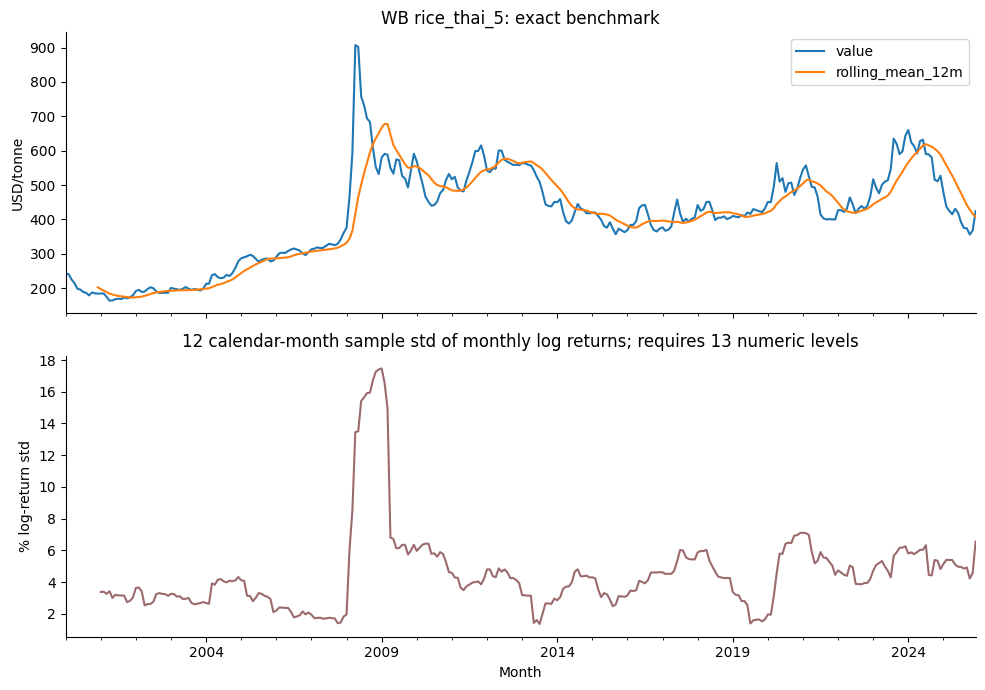

In [6]:
fig,axes=plt.subplots(2,1,figsize=(10,7),sharex=True)
wb_calendar[['value','rolling_mean_12m']].plot(ax=axes[0]);axes[0].set(title='WB rice_thai_5: exact benchmark',ylabel='USD/tonne')
wb_calendar.volatility_12m.plot(ax=axes[1],color='#9b6a6c');axes[1].set(title='12 calendar-month sample std of monthly log returns; requires 13 numeric levels',ylabel='% log-return std',xlabel='Month')
fig.tight_layout();plt.show();plt.close(fig)

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Rolling mean cần 12 numeric calendar months; volatility cần 12 returns. Gaps được giữ NaN; không forward-fill/interpolate.

In [7]:
wb_numeric=wb_calendar.value.dropna();hi=wb_numeric.idxmax();lo=wb_numeric.idxmin()
findings.append(dict(id='PR01',title='High/low của WB benchmark',observation=f"rice_thai_5, 2000–2025: high {wb_numeric.max():,.2f} USD/t tại {hi:%Y-%m}; low {wb_numeric.min():,.2f} USD/t tại {lo:%Y-%m}.",scope='World Bank rice_thai_5, USD/tonne, monthly',interpretation='Observed benchmark extrema; không đại diện mọi giống/grade hay giá nội địa Việt Nam.',query='price_observations',cell='Câu hỏi 1',numbers=dict(high=float(wb_numeric.max()),low=float(wb_numeric.min()),missing=int(wb_calendar.value.isna().sum()))))
vol=wb_calendar.volatility_12m.dropna()
findings.append(dict(id='PR02',title='Window volatility cao nhất',observation=f"Highest trailing 12-month log-return sample std: {vol.max():.2f}% tại {vol.idxmax():%Y-%m}.",scope='Same WB benchmark; complete-calendar 12 returns; ddof=1',interpretation='Historical variability, không là forecast hoặc causal event attribution.',query='price_observations',cell='Câu hỏi 1'))

## Câu hỏi 2 — Một domestic quote identity, không AVG các markets

In [8]:
vn_coverage=client.query('price_coverage',fact='fact_vn_market_quote_daily')
vn_candidates=vn_coverage[vn_coverage.currency.eq('VND')&vn_coverage.unit.eq('VND/kg')].sort_values(['numeric_observations','price_series_key'],ascending=[False,True])
# Choose strongest numeric coverage, never blend quotes or hide selected identity.
vn_series=vn_candidates.iloc[0]
daily=client.query('price_observations',fact='fact_vn_market_quote_daily',series=vn_series.price_series_key,start_period=20210101,end_period=20260803)

In [9]:
display(daily.shape,inspect_frame(daily),vn_series,daily.head())

(484, 12)

,dtype,nulls
observation_key,object,0
period,int64,0
reference_period,object,484
price_series_key,object,0
value,object,0
missing_reason,object,484
dq_warnings_json,object,0
series_identity_json,object,0
unit,object,0
currency,object,0


price_series_key        ad571f56ddde74e20951e6cb945da0c0333a2806733cb8...
series_identity_json    ["An Giang","Lúa IR 50404 (lúa tươi)","Thương ...
unit                                                               VND/kg
currency                                                              VND
price_kind                                                   market_quote
observations                                                          484
numeric_observations                                                  484
first_period                                                     20210401
last_period                                                      20260803
represented_periods                                                   484
Name: 274, dtype: object

,observation_key,period,reference_period,price_series_key,value,missing_reason,dq_warnings_json,series_identity_json,unit,currency,price_kind,information_source
0,4526c5215c7ea27354cb35799795c9bf394c920d40d554...,20250107,None,ad571f56ddde74e20951e6cb945da0c0333a2806733cb8...,7300.00,None,[],"[""An Giang"",""Lúa IR 50404 (lúa tươi)"",""Thương ...",VND/kg,VND,market_quote,CTV địa phương
1,7fb32c61b1b4bb3ee24dc14b0e3e303d382bd2cd7d896e...,20250108,None,ad571f56ddde74e20951e6cb945da0c0333a2806733cb8...,7300.00,None,[],"[""An Giang"",""Lúa IR 50404 (lúa tươi)"",""Thương ...",VND/kg,VND,market_quote,CTV địa phương
2,432ab9c3a5b2f5192c17ef2ce7468338c0f4373bed3dd6...,20250207,None,ad571f56ddde74e20951e6cb945da0c0333a2806733cb8...,5600.00,None,[],"[""An Giang"",""Lúa IR 50404 (lúa tươi)"",""Thương ...",VND/kg,VND,market_quote,CTV địa phương
3,2b53f589ab38e6034de055b740b37754574611574c6e3b...,20250212,None,ad571f56ddde74e20951e6cb945da0c0333a2806733cb8...,5500.00,None,[],"[""An Giang"",""Lúa IR 50404 (lúa tươi)"",""Thương ...",VND/kg,VND,market_quote,CTV địa phương
4,3ae5a8c91bb72d7a00349e01380a6740b81c8a83cdfa58...,20250221,None,ad571f56ddde74e20951e6cb945da0c0333a2806733cb8...,5600.00,None,[],"[""An Giang"",""Lúa IR 50404 (lúa tươi)"",""Thương ...",VND/kg,VND,market_quote,CTV địa phương


In [10]:
assert daily.price_series_key.nunique()==1 and not daily.period.duplicated().any()
daily['value']=pd.to_numeric(daily.value)
daily.index=pd.to_datetime(daily.period.astype(str),format='%Y%m%d')

In [11]:
daily_line=daily.value.reindex(pd.date_range(daily.index.min(),daily.index.max(),freq='D'))
display(daily.value.describe(),pd.DataFrame({'observed_dates':[len(daily)],'absent_calendar_days':[int(daily_line.isna().sum())]}))

count     484.000000
mean     6453.411157
std      1070.703688
min      4500.000000
25%      5600.000000
50%      6300.000000
75%      7200.000000
max      9400.000000
Name: value, dtype: float64

,observed_dates,absent_calendar_days
0,484,1467


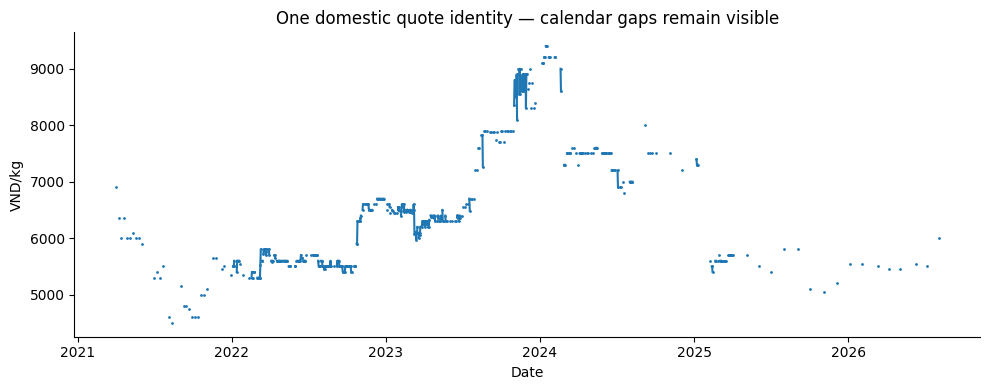

In [12]:
fig,ax=plt.subplots(figsize=(10,4));ax.plot(daily_line.index,daily_line.values,marker='.',markersize=2)
ax.set(title='One domestic quote identity — calendar gaps remain visible',ylabel='VND/kg',xlabel='Date');fig.tight_layout();plt.show();plt.close(fig)

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Calendar days không có quote không tự là pipeline lỗi. Series giữ nguyên market/commodity/price type/unit/currency/information source; không đổi sang USD/t.

In [13]:
findings.append(dict(id='PR03',title='Range của một domestic quote',observation=f"Selected exact identity có {len(daily)} quoted dates; numeric range {daily.value.min():,.2f}–{daily.value.max():,.2f} VND/kg trong {daily.index.min():%Y-%m-%d}–{daily.index.max():%Y-%m-%d}.",scope=str(vn_series.series_identity_json),interpretation='Chỉ đại diện quote identity được in; không phải mức giá trung bình thị trường hay toàn Việt Nam.',query='price_observations',cell='Câu hỏi 2'))

## Câu hỏi 3 — FAO annual/index và USDA reference prices có thể so trực tiếp không?

In [14]:
annual_coverage=client.query('price_coverage',fact='fact_fao_price_annual')
fao_series=annual_coverage[annual_coverage.price_kind.eq('producer_price_index')].sort_values(['numeric_observations','price_series_key'],ascending=[False,True]).iloc[0]
annual_index=client.query('price_observations',fact='fact_fao_price_annual',series=fao_series.price_series_key,start_period=1991,end_period=2025)
usda_series=series[series.series_identity_json.eq('["VIETNAM","5-PERCENT BROKEN","FREIGHT ON BOARD PRICE"]')].iloc[0]
reference=client.query('price_observations',fact='fact_usda_price_reference',series=usda_series.price_series_key,start_period=1985,end_period=2025)
display(annual_index.shape,inspect_frame(annual_index),fao_series,reference.shape,reference.groupby('reference_period').size())

(35, 12)

,dtype,nulls
observation_key,object,0
period,int64,0
reference_period,object,35
price_series_key,object,0
value,object,0
missing_reason,object,35
dq_warnings_json,object,0
series_identity_json,object,0
unit,object,0
currency,object,35


price_series_key        0a5853aa7eb408683e9ccf85d371ce5a296763c34835a2...
series_identity_json                                ["364","0113","5539"]
unit                                                 index(2014-2016=100)
currency                                                             None
price_kind                                           producer_price_index
observations                                                           35
numeric_observations                                                   35
first_period                                                         1991
last_period                                                          2025
represented_periods                                                    35
Name: 319, dtype: object

(372, 12)

reference_period
April        28
August       29
December     29
February     29
January      29
July         28
June         28
MARKETING    29
March        28
May          28
November     29
October      29
September    29
dtype: int64

In [15]:
assert len(annual_index)>1 and annual_index.price_kind.eq('producer_price_index').all()
annual_index['value']=pd.to_numeric(annual_index.value)
assert not reference.duplicated(['period','reference_period']).any()
display(annual_index[['period','value','unit','price_kind']],reference.groupby('reference_period').value.agg(['size','count']))

,period,value,unit,price_kind
0,2023,926.47,index(2014-2016=100),producer_price_index
1,2024,991.94,index(2014-2016=100),producer_price_index
2,2025,1561.06,index(2014-2016=100),producer_price_index
3,2015,92.58,index(2014-2016=100),producer_price_index
4,2016,125.56,index(2014-2016=100),producer_price_index
5,2017,139.24,index(2014-2016=100),producer_price_index
6,2018,169.88,index(2014-2016=100),producer_price_index
7,1995,5.51,index(2014-2016=100),producer_price_index
8,1996,3.73,index(2014-2016=100),producer_price_index
9,1997,3.84,index(2014-2016=100),producer_price_index


,size,count
reference_period,,
April,28,27
August,29,28
December,29,25
February,29,28
January,29,28
July,28,27
June,28,27
MARKETING,29,29
March,28,28


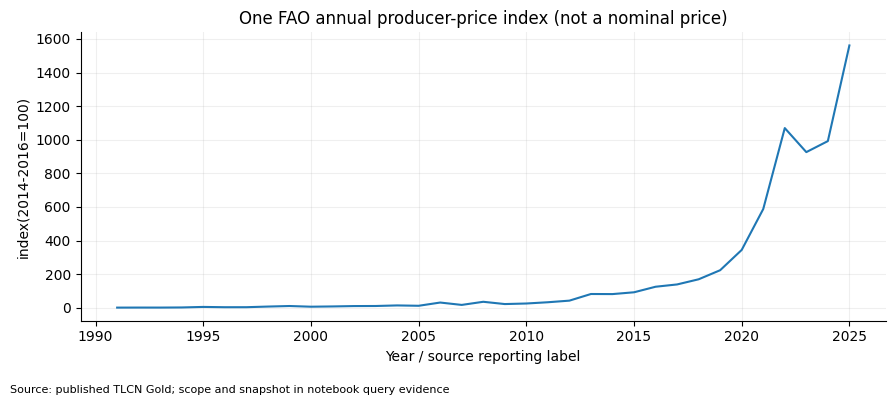

In [16]:
annual_plot(annual_index,'value','One FAO annual producer-price index (not a nominal price)',str(fao_series.unit),year='period')

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Annual indices không là nominal prices; USDA reference_period không tự suy monthly calendar. Hai datasets được kiểm tra riêng, không đưa chung vào monthly price chart. Seasonality chỉ là hypothesis cần đủ năm liên tục, chưa kết luận từ chart tổng quan.

## Key Findings

Measured batch `ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235`.

### PR01 — High/low của WB benchmark

**OBSERVATION:** rice_thai_5, 2000–2025: high 907.00 USD/t tại 2008-04; low 163.75 USD/t tại 2001-04.

**Scope:** World Bank rice_thai_5, USD/tonne, monthly

**INTERPRETATION / LIMITATION:** Observed benchmark extrema; không đại diện mọi giống/grade hay giá nội địa Việt Nam.

**Reproduce:** query `price_observations`, Câu hỏi 1.

### PR02 — Window volatility cao nhất

**OBSERVATION:** Highest trailing 12-month log-return sample std: 17.47% tại 2009-01.

**Scope:** Same WB benchmark; complete-calendar 12 returns; ddof=1

**INTERPRETATION / LIMITATION:** Historical variability, không là forecast hoặc causal event attribution.

**Reproduce:** query `price_observations`, Câu hỏi 1.

### PR03 — Range của một domestic quote

**OBSERVATION:** Selected exact identity có 484 quoted dates; numeric range 4,500.00–9,400.00 VND/kg trong 2021-04-01–2026-08-03.

**Scope:** ["An Giang","Lúa IR 50404 (lúa tươi)","Thương lái thu mua","VND/kg","VND","CTV địa phương"]

**INTERPRETATION / LIMITATION:** Chỉ đại diện quote identity được in; không phải mức giá trung bình thị trường hay toàn Việt Nam.

**Reproduce:** query `price_observations`, Câu hỏi 2.

## Limitations

Không FX/currency conversion. Không interpolate. Benchmark movements không chứng minh causality. Chưa kiểm định seasonality, không dùng 12-month volatility làm dự báo.

In [17]:
print(save_evidence(ROOT, '04_rice_price_analysis', client, findings))
print('Query audit:')
display(pd.DataFrame(client.evidence)[['query','row_count','query_seconds','response_bytes','batch']])

docs/analytics/evidence/04_rice_price_analysis.json
Query audit:


,query,row_count,query_seconds,response_bytes,batch
0,publication,17,0.000000,4333,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
1,catalogue,1042,0.072399,440911,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
2,price_observations,312,0.433213,80146,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
3,price_coverage,542,0.368120,132724,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
4,price_observations,484,0.138331,175025,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
5,price_coverage,396,0.323875,70011,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
6,price_observations,35,0.178747,13880,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
7,price_observations,372,0.154631,113504,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
